In [6]:
import time
import pandas as pd
from mplsoccer import Radar
import undetected_chromedriver as uc
import lxml
from io import StringIO
import html5lib
import matplotlib.pyplot as plt

In [7]:
# initialize the undetected Chrome driver
driver = uc.Chrome(version_main=155)

# navigate to the URL
driver.get("https://fbref.com/en/comps/Big5/stats/players/Big-5-European-Leagues-Stats")

In [8]:
time.sleep(45)

In [9]:
# get the table with id "big5_table" from the page source for the Big 5 European Leagues Stats untill
players_df = pd.read_html(
    StringIO(driver.page_source),
    attrs={"id": "stats_standard"},
)[0]

players_df.head()

The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


Unnamed: 0_level_0 Unnamed: 1_level_0 Unnamed: 2_level_0 Unnamed: 3_level_0  \
                  Rk             Player             Nation                Pos   
0                  1   Brenden Aaronson             us USA                 MF   
1                  2      Haitam Abaida             ma MAR                 FW   
2                  3     James Abankwah             ie IRL                 DF   
3                  4  Keyliane Abdallah             fr FRA                 FW   
4                  5   Hamza Abdelkarim             eg EGY                 FW   

  Unnamed: 4_level_0  Unnamed: 5_level_0 Unnamed: 6_level_0  \
               Squad                Comp                Age   
0       Leeds United  eng Premier League             26-023   
1             Málaga          es La Liga             24-166   
2            Udinese          it Serie A             22-302   
3          Marseille          fr Ligue 1             20-223   
4          Barcelona          es La Liga             18-317   

  Unnamed: 7_level_0 Playing Time         ... Performance                  \
                Born           MP Starts  ...          PK PKatt CrdY CrdR   
0               2000            8      3  ...           0     0    0    0   
1               2002            3      0  ...           0     0    0    0   
2               2004           10     10  ...           0     0    1    0   
3               2006            9      0  ...           0     0    1    0   
4               2008            2      0  ...           0     0    0    0   

  Per 90 Minutes                          Unnamed: 25_level_0  
             Gls   Ast   G+A  G-PK G+A-PK             Matches  
0           0.00  0.00  0.00  0.00   0.00             Matches  
1           0.00  0.00  0.00  0.00   0.00             Matches  
2           0.11  0.00  0.11  0.11   0.11             Matches  
3           0.95  0.00  0.95  0.95   0.95             Matches  
4           0.00  0.00  0.00  0.00   0.00             Matches  

[5 rows x 26 columns]

In [10]:
# drop per 90 columns
players_stats_df = players_df[players_df.columns.drop(list(players_df.filter(regex='Per 90')))]

# drop the first level of the multi-level column index
players_stats_clean_df = players_stats_df.droplevel(0, axis=1)

# get the nation of the players by splitting the 'Nation' column by space and taking the last element, then stripping any whitespace
players_stats_clean_df['Nation'] = players_stats_clean_df['Nation'].str.split(' ').str[-1].str.strip()

# drop the 'Matches' column from the DataFrame
players_stats_clean_df.drop(columns=['Matches'], inplace=True)
players_stats_clean_df.head(3)

#players_stats_clean_df.head(3)
#players_stats_df.head(3)

,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,90s,Gls,Ast,G+A,G-PK,PK,PKatt,CrdY,CrdR
0,1,Brenden Aaronson,USA,MF,Leeds United,eng Premier League,26-023,2000,8,3,289,3.2,0,0,0,0,0,0,0,0
1,2,Haitam Abaida,MAR,FW,Málaga,es La Liga,24-166,2002,3,0,44,0.5,0,0,0,0,0,0,0,0
2,3,James Abankwah,IRL,DF,Udinese,it Serie A,22-302,2004,10,10,837,9.3,1,0,1,1,0,0,1,0


In [11]:
# Remove rows where 'Player' is 'Player' and 'Nation' is 'Nation'
players_stats_clean_df = players_stats_clean_df[
    ~((players_stats_clean_df['Player'] == 'Player') & (players_stats_clean_df['Nation'] == 'Nation'))
]

players_stats_clean_df.shape

(2319, 20)

In [12]:
# Clean the DataFrame by converting the data types of the columns to the appropriate types
players_stats_clean_df = players_stats_clean_df.astype({
    'Nation': 'str',
    'MP': 'int',
    'Starts': 'int',
    '90s': 'float',
    'Min': 'float',
    'Gls': 'int',
    'Ast': 'int',
    'G+A': 'int',
    'PK': 'int',
    'PKatt': 'int',
    'CrdY': 'int',
    'CrdR': 'int',
    'G-PK': 'int',
})

players_stats_clean_df.dtypes

Rk            str
Player        str
Nation        str
Pos           str
Squad         str
Comp          str
Age           str
Born          str
MP          int64
Starts      int64
Min       float64
90s       float64
Gls         int64
Ast         int64
G+A         int64
G-PK        int64
PK          int64
PKatt       int64
CrdY        int64
CrdR        int64
dtype: object

In [13]:
# Forward players who played 400 minutes or more in the season
forward_players_df = players_stats_clean_df[(players_stats_clean_df['Pos'].str.contains('FW')) & (players_stats_clean_df['Min'] >= 400)]
forward_players_df.head(3)

,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,90s,Gls,Ast,G+A,G-PK,PK,PKatt,CrdY,CrdR
10,11,Matthis Abline,FRA,"FW,MF",Monaco,fr Ligue 1,23-231,2003,9,5,507.0,5.6,1,1,2,1,0,0,0,0
19,20,Akor Adams,NGA,FW,Venezia,it Serie A,26-289,2000,11,11,943.0,10.5,2,0,2,2,0,0,0,0
20,21,Ché Adams,SCO,"FW,MF",Torino,it Serie A,30-124,1996,9,7,613.0,6.8,4,0,4,4,0,0,0,0


In [14]:
# FW Players Stats per 90 minutes
forward_players_df['Gls_per_90'] = forward_players_df['Gls'] / forward_players_df['90s']
forward_players_df['Ast_per_90'] = forward_players_df['Ast'] / forward_players_df['90s']
forward_players_df['G-PK_per_90'] = forward_players_df['G-PK'] / forward_players_df['90s'] # Goals excluding penalties per 90 minutes
forward_players_df['G+A_per_90'] = forward_players_df['G+A'] / forward_players_df['90s']
forward_players_df['PKatt_per_90'] = forward_players_df['PKatt'] / forward_players_df['90s'] # Penalty kicks attempted per 90 minutes
forward_players_df['G+A-PK_per_90'] = forward_players_df['G-PK_per_90'] + forward_players_df['Ast_per_90'] # Non Penalty Goals and Assests attempted per 90 minutes

forward_players_df[[
        'Player', 
        'Gls_per_90', 
        'Ast_per_90',
        'G-PK_per_90',
        'G+A_per_90',
        'PKatt_per_90',
        'G+A-PK_per_90'
    ]] \
    .sort_values('Gls_per_90', ascending=False) \
    .round(2) \
    .head(3)

,Player,Gls_per_90,Ast_per_90,G-PK_per_90,G+A_per_90,PKatt_per_90,G+A-PK_per_90
1844,Raphinha,1.67,0.33,1.33,2.00,0.33,1.67
1264,Esteban Lepaul,1.17,0.00,0.50,1.17,0.67,0.50
1356,Donyell Malen,1.11,0.28,1.11,1.39,0.00,1.39


In [15]:
# creates a new column called Goals, but it does not store the actual number of goals scored. 
# It stores a percentile-based performance score for each forward based on their goals per 90 minutes.
# Create a "Goals" performance score based on how a forward compares
# to other forwards in the dataset for goals per 90 minutes.
#
# rank(pct=True) gives each player's percentile rank from 0 to 1:
#   0.95 means "top 5%" among all forwards
# Multiply by 100 to turn it into a 0-100 score, then cast to int
# so the score is easy to read and use in sorting/filtering.
forward_players_df['Goals'] = (
    forward_players_df['Gls_per_90'].rank(pct=True) * 100
).astype(int)

# Create a "Assists" performance score based on how a forward compares
# to other forwards in the dataset for assists per 90 minutes.
forward_players_df['Assists'] = (
    forward_players_df['Ast_per_90'].rank(pct=True) * 100
).astype(int)

# Create a "Goals + Assists" performance score based on how a forward compares
# to other forwards in the dataset for combined goals and assists per 90 minutes.
forward_players_df['Goals + Assists'] = (
    forward_players_df['G+A_per_90'].rank(pct=True) * 100
).astype(int)

# Create a "No Penalty Goals" performance score based on how a forward compares
# to other forwards in the dataset for goals excluding penalties per 90 minutes.
forward_players_df['No Penalty Goals'] = (
    forward_players_df['G-PK_per_90'].rank(pct=True) * 100
).astype(int)

# Create a "No Penalty Goals + Assists" performance score based on how a forward compares
# to other forwards in the dataset for combined goals excluding penalties and assists per 90 minutes.
forward_players_df['No Penalty Goals + Assists'] = (
    forward_players_df['G+A-PK_per_90'].rank(pct=True) * 100
).astype(int)


In [16]:
# Get the stats for Kylian Mbappé
Kylian_Mbappe = forward_players_df[forward_players_df['Player'] == 'Kylian Mbappé']
Kylian_Mbappe

,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,...,Ast_per_90,G-PK_per_90,G+A_per_90,PKatt_per_90,G+A-PK_per_90,Goals,Assists,Goals + Assists,No Penalty Goals,No Penalty Goals + Assists
1440,1386,Kylian Mbappé,FRA,FW,Real Madrid,es La Liga,27-329,1998,12,12,...,0.168067,0.840336,1.260504,0.336134,1.008403,98,59,95,94,91


In [17]:
# Get the percentile performance scores for Kylian Mbappé in the following categories: Goals, Assists, Goals + Assists, 
# No Penalty Goals, and No Penalty Goals + Assists Among all forwards in the Big 5 European Leagues.
mbappe_cols_toplot = [
    'Goals',
    'Assists',
    'Goals + Assists',
    'No Penalty Goals',
    'No Penalty Goals + Assists'
]

# Initialize the radar chart with the specified parameters
radar = Radar(
    params=mbappe_cols_toplot,
    min_range=[0] * len(mbappe_cols_toplot),
    max_range=[100] * len(mbappe_cols_toplot)
)

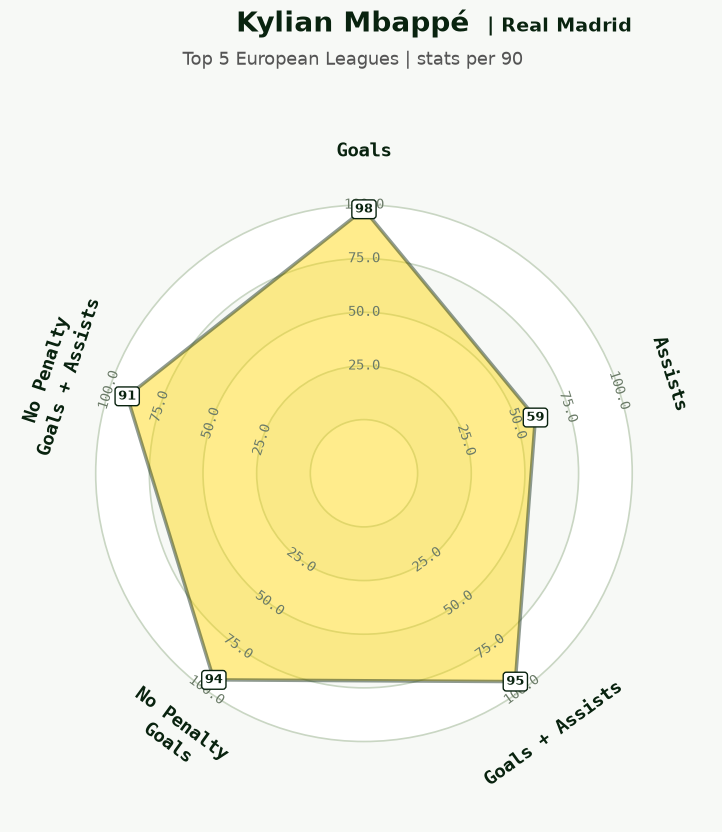

In [18]:
# Plotting the radar chart for Kylian Mbappé's performance scores in the specified categories

# Define colors
GOLD = "#FFD700"
DARK = "#09230F"
BG = "#F7F9F6"
GRID = "#C9D6C3"

# Get the values for Kylian Mbappé's performance scores in the specified categories
values = list(Kylian_Mbappe[mbappe_cols_toplot].values.flatten())

# Create the axes used by the radar chart (keep your existing `radar` object).
fig, ax = radar.setup_axis()
fig.set_size_inches(9, 9.5)
fig.set_facecolor(BG)
ax.set_facecolor(BG)

# Soft range rings behind the data shape.
rings_inner = radar.draw_circles(
    ax=ax,
    facecolor="white",
    edgecolor=GRID,
    lw=1.2,
    zorder=1
)

# Player shape: translucent fill, strong outline.
radar_output = radar.draw_radar(
    ax=ax,
    values=values,
    kwargs_radar={
        "facecolor": GOLD,
        "edgecolor": DARK,
        "alpha": 0.45,
        "linewidth": 2.5
    },
    kwargs_rings={            # outer ring of the "last" shape (hidden for a cleaner look)
        "facecolor": "none",
        "edgecolor": "none",
    },
)
radar_poly, rings_outer, vertices = radar_output

# Dots at each vertex.
ax.scatter(
    vertices[:, 0], vertices[:, 1],
    s=70, c=GOLD, edgecolors=DARK, linewidths=1.5, zorder=5
)

# Value badges on each vertex.
for (x, y), v in zip(vertices, values):
    ax.text(
        x, y, f"{v:.0f}",
        ha="center", va="center", fontsize=9, fontweight="bold",
        color=DARK, zorder=6,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white",
                  edgecolor=DARK, linewidth=1),
    )

# Range ring labels: small and muted so they don't compete with the data.
range_labels = radar.draw_range_labels(
    ax=ax,
    fontsize=10,
    color="#6B7B68",
    fontproperties="monospace"
)

# Metric labels: larger and bold for readability on a projector.
param_labels = radar.draw_param_labels(
    ax=ax,
    fontsize=14,
    color=DARK,
    fontweight="bold",
    fontproperties="monospace"
)

# Title and subtitle.
fig.text(0.5, 0.96, "Kylian Mbappé", ha="center", fontsize=20,
         fontweight="bold", color=DARK)
fig.text(0.73, 0.96, "| Real Madrid", ha="center", fontsize=14,
         fontweight="bold", color=DARK)            
fig.text(0.5, 0.925, "Top 5 European Leagues | stats per 90", ha="center",
         fontsize=13, color="#555555")

plt.show()

### Kylian Mbappé Attacking Performance for this Seasson

#### What the chart shows

This radar chart summarizes Mbappé's attacking output across the Top 5 European Leagues (stats per 90 minutes) on five metrics. Each axis runs from the center (0) to the outer ring (100). The further a point sits toward the edge, the better he ranks on that metric. The values appear to be **percentiles**: a score of 98 means he outperforms about 98% of the comparison group.

#### Radar Specifications

- **Each spoke** is one metric: Goals, Assists, Goals + Assists, No Penalty Goals, and No Penalty Goals + Assists.
- **The rings** (25, 50, 75, 100) are reference levels. The outer ring is the best possible score.
- **The green shape** connects his five scores. A bigger, more circular shape means a stronger all-round profile.

### The key numbers

| Metric | Score | Meaning |
| --- | --- | --- |
| Goals | 98 | Elite, among the very top scorers |
| Goals + Assists | 95 | Elite overall attacking output |
| No Penalty Goals | 92 | Still elite without penalties |
| No Penalty Goals + Assists | 90 | Elite output from open play |
| Assists | 62 | Above average, but his weakest area |

#### Conclusion points

1. **"He is a goal scorer first."** The shape stretches furthest toward Goals (98), so his main value is finishing.
2. **"The numbers are not inflated by penalties."** His no-penalty goals (92) are only slightly below his total goals (98). This means most of his scoring comes from open play, not spot kicks.
3. **"Creating for teammates is his smaller contribution."** Assists (62) is the one clear dip in the shape. He is above the median, but this is a gap compared with his scoring.
4. **"Overall, he is a top-tier attacker."** Three of five metrics are above 90, so he combines volume and efficiency at the highest level.


> "Mbappé's profile is that of an elite finisher. He ranks in the top 10% or better for every goal-based metric, and his main room for growth is in creating chances for others."

#### Radar Reading

- **Percentiles show rank, not raw totals.** A 98 does not mean 98 goals. It means he ranks higher than 98% of players in the comparison group.
- **Per 90 minutes** makes the comparison fair between players who play different amounts of time.
- **The metrics overlap.** Goals + Assists is built from the other two, so the shape is naturally tied together. Five axes is also a small number, so the chart shows attacking output only, not defending, passing, or dribbling.


  ------------------------------------------------
  ------------------------------------------------

In [19]:
# Get the stats for Raphinha
Raphinha = forward_players_df[forward_players_df['Player'] == 'Raphinha']
Raphinha

# Get the percentile performance scores for Raphinha in the following categories: Goals, Assists, Goals + Assists, 
# No Penalty Goals, and No Penalty Goals + Assists.
raphinha_cols_toplot = [
    'Goals',
    'Assists',
    'Goals + Assists',
    'No Penalty Goals',
    'No Penalty Goals + Assists'
]

# Initialize the radar chart with the specified parameters
radar = Radar(
    params=raphinha_cols_toplot,
    min_range=[0] * len(raphinha_cols_toplot),
    max_range=[100] * len(raphinha_cols_toplot)
)

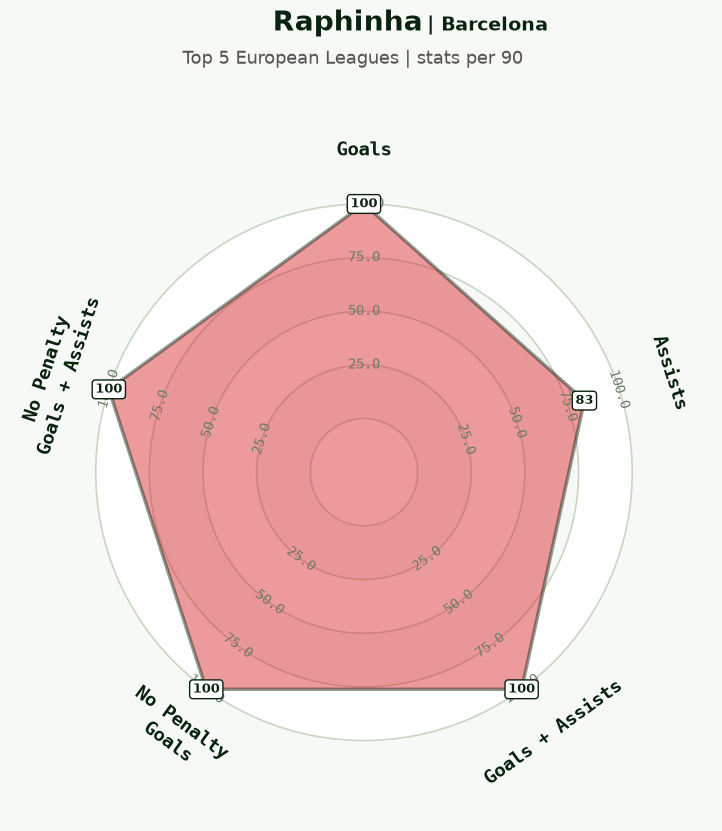

In [20]:
# Plotting the radar chart for Raphinha's performance scores in the specified categories

# Define colors 
RED = "#D81F26"
DARK = "#09230F"
BG = "#F7F9F6"
GRID = "#C9D6C3"

# Get the values for Raphinha's performance scores in the specified categories
values = list(Raphinha[raphinha_cols_toplot].values.flatten())

# Create the axes used by the radar chart (keep your existing `radar` object).
fig, ax = radar.setup_axis()
fig.set_size_inches(9, 9.5)
fig.set_facecolor(BG)
ax.set_facecolor(BG)

# Soft range rings behind the data shape.
rings_inner = radar.draw_circles(
    ax=ax,
    facecolor="white",
    edgecolor=GRID,
    lw=1.2,
    zorder=1
)

# Player shape: translucent fill, strong outline.
radar_output = radar.draw_radar(
    ax=ax,
    values=values,
    kwargs_radar={
        "facecolor": RED,
        "edgecolor": DARK,
        "alpha": 0.45,
        "linewidth": 2.5
    },
    kwargs_rings={            # outer ring of the "last" shape (hidden for a cleaner look)
        "facecolor": "none",
        "edgecolor": "none",
    },
)
radar_poly, rings_outer, vertices = radar_output

# Dots at each vertex.
ax.scatter(
    vertices[:, 0], vertices[:, 1],
    s=70, c=RED, edgecolors=DARK, linewidths=1.5, zorder=5
)

# Value badges on each vertex.
for (x, y), v in zip(vertices, values):
    ax.text(
        x, y, f"{v:.0f}",
        ha="center", va="center", fontsize=9, fontweight="bold",
        color=DARK, zorder=6,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white",
                  edgecolor=DARK, linewidth=1),
    )

# Range ring labels: small and muted so they don't compete with the data.
range_labels = radar.draw_range_labels(
    ax=ax,
    fontsize=10,
    color="#6B7B68",
    fontproperties="monospace"
)

# Metric labels: larger and bold for readability on a projector.
param_labels = radar.draw_param_labels(
    ax=ax,
    fontsize=14,
    color=DARK,
    fontweight="bold",
    fontproperties="monospace"
)

# Title and subtitle.
fig.text(0.5, 0.96, "Raphinha ", ha="center", fontsize=20,
         fontweight="bold", color=DARK)
fig.text(0.65, 0.96, "| Barcelona", ha="center", fontsize=14,
         fontweight="bold", color=DARK)         
fig.text(0.5, 0.925, "Top 5 European Leagues | stats per 90", ha="center",
         fontsize=13, color="#555555")

plt.show()

### Raphinha Attacking Performance for this Seasson

#### What the chart shows

This radar chart summarizes Raphinha's attacking output in the Top 5 European Leagues (stats per 90 minutes) across five metrics: Goals, Assists, Goals + Assists, No Penalty Goals, and No Penalty Goals + Assists. Each axis runs from the center (0) to the outer ring (100). The values look like **percentiles**: a score of 100 means he ranks at the top of the comparison group.

#### The key numbers

| Metric | Score | Meaning |
| --- | --- | --- |
| Goals | 100 | Top of the group |
| No Penalty Goals | 100 | Top of the group, even without penalties |
| Goals + Assists | 100 | Top overall attacking output |
| No Penalty Goals + Assists | 100 | Top open-play output |
| Assists | 86 | Strong, but his lowest score |

#### Talking points

1. **"His shape almost fills the chart."** He reaches the outer ring on four of five axes, which is the profile of an elite attacker.
2. **"He is a finisher first."** Goals and No Penalty Goals are both 100, so his scoring is not inflated by penalties.
3. **"He also creates."** An 86 in Assists is well above average, even though it is his one dip.
4. **"His total contribution is top-tier."** Both combined metrics are 100, so his goals and assists together rank at the top.

#### Conclusion

> "Raphinha ranks at the very top of Europe's top five leagues for scoring and combined output, with assists as a solid secondary strength."


--------------------------------------------------------
--------------------------------------------------------


In [21]:
# Get the stats for Lamin_Yamal
Lamin_Yamal = forward_players_df[forward_players_df['Player'] == 'Lamine Yamal']
Lamin_Yamal

# Get the percentile performance scores for Lamin_Yamal in the following categories: Goals, Assists, Goals + Assists, 
# No Penalty Goals, and No Penalty Goals + Assists.
lamin_yamal_cols_toplot = [
    'Goals',
    'Assists',
    'Goals + Assists',
    'No Penalty Goals',
    'No Penalty Goals + Assists'
]

# Initialize the radar chart with the specified parameters
radar = Radar(
    params=lamin_yamal_cols_toplot,
    min_range=[0] * len(lamin_yamal_cols_toplot),
    max_range=[100] * len(lamin_yamal_cols_toplot)
)
Lamin_Yamal

,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,...,Ast_per_90,G-PK_per_90,G+A_per_90,PKatt_per_90,G+A-PK_per_90,Goals,Assists,Goals + Assists,No Penalty Goals,No Penalty Goals + Assists
2360,2271,Lamine Yamal,ESP,"FW,MF",Barcelona,es La Liga,19-124,2007,12,12,...,0.727273,0.818182,1.636364,0.181818,1.545455,93,97,99,93,99


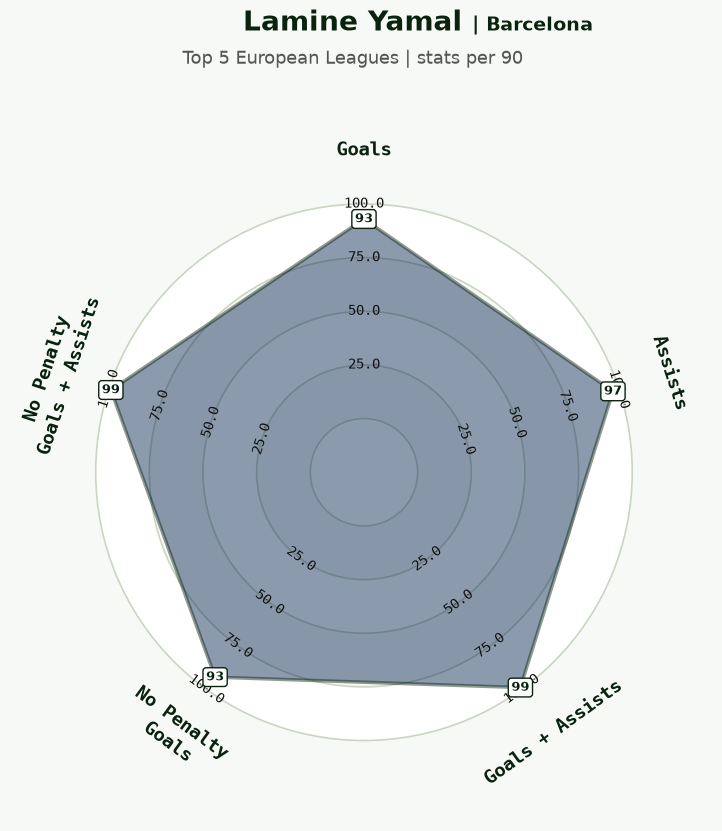

In [22]:
# Plotting the radar chart for Lamin_Yamal's performance scores in the specified categories

# Define colors
BLUE = "#011F4B"
DARK = "#09230F"
BG = "#F7F9F6"
GRID = "#C9D6C3"

values = list(Lamin_Yamal[lamin_yamal_cols_toplot].values.flatten())

# Create the axes used by the radar chart (keep your existing `radar` object).
fig, ax = radar.setup_axis()
fig.set_size_inches(9, 9.5)
fig.set_facecolor(BG)
ax.set_facecolor(BG)

# Soft range rings behind the data shape.
rings_inner = radar.draw_circles(
    ax=ax,
    facecolor="white",
    edgecolor=GRID,
    lw=1.2,
    zorder=1
)

# Player shape: translucent fill, strong outline.
radar_output = radar.draw_radar(
    ax=ax,
    values=values,
    kwargs_radar={
        "facecolor": BLUE,
        "edgecolor": DARK,
        "alpha": 0.45,
        "linewidth": 2.5
    },
    kwargs_rings={            # outer ring of the "last" shape (hidden for a cleaner look)
        "facecolor": "none",
        "edgecolor": "none",
    },
)
radar_poly, rings_outer, vertices = radar_output

# Dots at each vertex.
ax.scatter(
    vertices[:, 0], vertices[:, 1],
    s=70, c=BLUE, edgecolors=DARK, linewidths=1.5, zorder=5
)

# Value badges on each vertex.
for (x, y), v in zip(vertices, values):
    ax.text(
        x, y, f"{v:.0f}",
        ha="center", va="center", fontsize=9, fontweight="bold",
        color=DARK, zorder=6,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white",
                  edgecolor=DARK, linewidth=1),
    )

# Range ring labels: small and muted so they don't compete with the data.
range_labels = radar.draw_range_labels(
    ax=ax,
    fontsize=10,
    color="#111111",
    fontproperties="monospace"
)

# Metric labels: larger and bold for readability on a projector.
param_labels = radar.draw_param_labels(
    ax=ax,
    fontsize=14,
    color=DARK,
    fontweight="bold",
    fontproperties="monospace"
)

# Title and subtitle.
fig.text(0.5, 0.96, "Lamine Yamal", ha="center", fontsize=20,
         fontweight="bold", color=DARK)
fig.text(0.70, 0.96, "| Barcelona", ha="center", fontsize=14,
         fontweight="bold", color=DARK)            
fig.text(0.5, 0.925, "Top 5 European Leagues | stats per 90", ha="center",
         fontsize=13, color="#555555")

plt.show()

### Lamine Yamal Attacking Performance for this Seasson

### What the chart shows

This radar chart summarizes Lamine Yamal's attacking output in the Top 5 European Leagues (stats per 90 minutes) across the same five metrics. Each axis runs from the center (0) to the outer ring (100). The values look like **percentiles**: a score of 97 means he ranks higher than about 97% of the comparison group.

### The key numbers

| Metric | Score | Meaning |
| --- | --- | --- |
| Assists | 97 | Elite chance creator |
| Goals + Assists | 99 | Near the very top overall |
| No Penalty Goals + Assists | 99 | Near the very top in open play |
| No Penalty Goals | 96 | Elite scorer without penalties |
| Goals | 95 | Elite scorer |

### Talking points

1. **"His shape is almost a perfect pentagon."** Every score sits between 95 and 99, so he has no weak area on these metrics.
2. **"He creates as well as he scores."** His 97 in Assists is his highest single-metric score, which is unusual for someone who also scores at a 95 level.
3. **"The combined numbers are exceptional."** A 99 in both Goals + Assists and No Penalty Goals + Assists puts his overall output near the top of the group.
4. **"The output is not penalty-driven."** His No Penalty Goals (96) is almost the same as his Goals (95), so his production comes from open play.

### Closing line

> "Lamine Yamal's profile is complete: he ranks in the top 5% for both scoring and creating, with no weak spot in his attacking output."



---------------------------------------------------
---------------------------------------------------


In [23]:
# Get the stats for Haaland
Haaland = forward_players_df[forward_players_df['Player'] == 'Erling Haaland']
Haaland

# Get the percentile performance scores for Haaland in the following categories: Goals, Assists, Goals + Assists, 
# No Penalty Goals, and No Penalty Goals + Assists.
haaland_cols_toplot = [
    'Goals',
    'Assists',
    'Goals + Assists',
    'No Penalty Goals',
    'No Penalty Goals + Assists'
]

# Initialize the radar chart with the specified parameters
radar = Radar(
    params=haaland_cols_toplot,
    min_range=[0] * len(haaland_cols_toplot),
    max_range=[100] * len(haaland_cols_toplot)
)
Haaland[['Ast', 'Gls']]

,Ast,Gls
929,0,9


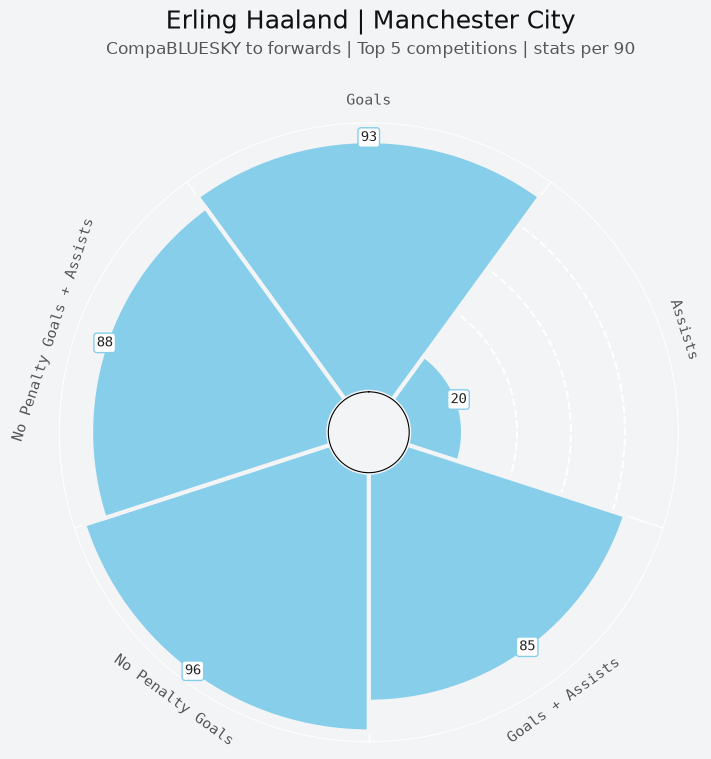

In [24]:
from mplsoccer import PyPizza
import matplotlib.pyplot as plt

params = list(haaland_cols_toplot)  # same metric order as before
values = list(Haaland[haaland_cols_toplot].values.flatten())

BLUESKY = "#87CEEB"  # sky blue
BG = "#F2F4F6"

pizza = PyPizza(
    params=params,
    background_color=BG,
    straight_line_color="white",   # lines between slices
    straight_line_lw=1,
    last_circle_color="white",
    last_circle_lw=1.5,            # outer ring
    other_circle_color="white",
    other_circle_lw=1.5,
    other_circle_ls="--",          # dashed inner rings like your image
    inner_circle_size=15,          # hole in the middle
)

fig, ax = pizza.make_pizza(
    values,
    figsize=(8, 8.5),
    slice_colors=[BLUESKY] * len(params),
    value_colors=["#222222"] * len(params),
    value_bck_colors=["white"] * len(params),
    kwargs_slices=dict(edgecolor=BG, linewidth=3, zorder=2),
    kwargs_params=dict(color="#555555", fontsize=11, fontproperties="monospace", va="center"),
    kwargs_values=dict(
        fontsize=10, zorder=3, fontproperties="monospace",
        bbox=dict(edgecolor=BLUESKY, facecolor="white", boxstyle="round,pad=0.2", lw=1),
    ),
)

fig.text(0.515, 0.97, "Erling Haaland | Manchester City", size=18, ha="center", color="#111111")
fig.text(0.515, 0.94, "CompaBLUESKY to forwards | Top 5 competitions | stats per 90",
         size=12, ha="center", color="#555555")

plt.show()

In [25]:
fig.savefig("EPL_2023_24_Haaland_Performance.png", dpi=300, bbox_inches="tight")

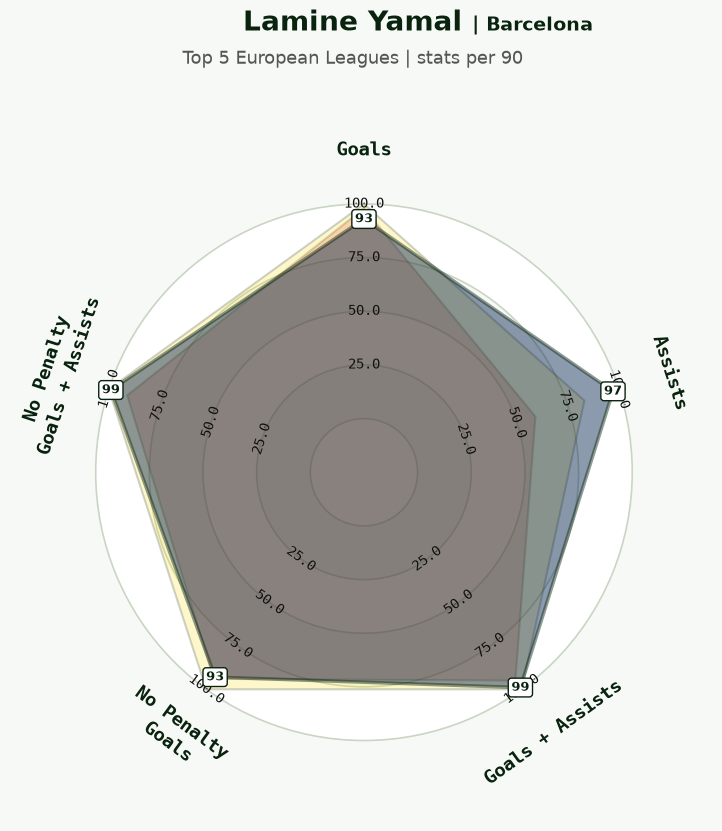

In [26]:
# Plotting the radar chart for Lamin_Yamal's performance scores in the specified categories

# Define colors
BLUE = "#011F4B"
DARK = "#09230F"
BG = "#F7F9F6"
GRID = "#C9D6C3"

values = list(Lamin_Yamal[lamin_yamal_cols_toplot].values.flatten())

# Create the axes used by the radar chart (keep your existing `radar` object).
fig, ax = radar.setup_axis()
fig.set_size_inches(9, 9.5)
fig.set_facecolor(BG)
ax.set_facecolor(BG)

# Soft range rings behind the data shape.
rings_inner = radar.draw_circles(
    ax=ax,
    facecolor="white",
    edgecolor=GRID,
    lw=1.2,
    zorder=1
)

# Player shape: translucent fill, strong outline.
# Draw comparison players first so Lamine Yamal remains visible on top.
radar.draw_radar(
    ax=ax,
    values=list(Kylian_Mbappe[mbappe_cols_toplot].values.flatten()),
    kwargs_radar={"facecolor": RED, "edgecolor": DARK, "alpha": 0.2, "linewidth": 1.5},
    kwargs_rings={"facecolor": "none", "edgecolor": "none"},
)

radar.draw_radar(
    ax=ax,
    values=list(Raphinha[raphinha_cols_toplot].values.flatten()),
    kwargs_radar={"facecolor": GOLD, "edgecolor": DARK, "alpha": 0.2, "linewidth": 1.5},
    kwargs_rings={"facecolor": "none", "edgecolor": "none"},
)

# Keep this output for the existing unpacking and Yamal vertex labels below.
radar_output = radar.draw_radar(
    ax=ax,
    values=values,
    kwargs_radar={
        "facecolor": BLUE,
        "edgecolor": DARK,
        "alpha": 0.45,
        "linewidth": 2.5,
    },
    kwargs_rings={"facecolor": "none", "edgecolor": "none"},
)
radar_poly, rings_outer, vertices = radar_output

# Dots at each vertex.
ax.scatter(
    vertices[:, 0], vertices[:, 1],
    s=70, c=BLUE, edgecolors=DARK, linewidths=1.5, zorder=5
)

# Value badges on each vertex.
for (x, y), v in zip(vertices, values):
    ax.text(
        x, y, f"{v:.0f}",
        ha="center", va="center", fontsize=9, fontweight="bold",
        color=DARK, zorder=6,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white",
                  edgecolor=DARK, linewidth=1),
    )

# Range ring labels: small and muted so they don't compete with the data.
range_labels = radar.draw_range_labels(
    ax=ax,
    fontsize=10,
    color="#111111",
    fontproperties="monospace"
)

# Metric labels: larger and bold for readability on a projector.
param_labels = radar.draw_param_labels(
    ax=ax,
    fontsize=14,
    color=DARK,
    fontweight="bold",
    fontproperties="monospace"
)

# Title and subtitle.
fig.text(0.5, 0.96, "Lamine Yamal", ha="center", fontsize=20,
         fontweight="bold", color=DARK)
fig.text(0.70, 0.96, "| Barcelona", ha="center", fontsize=14,
         fontweight="bold", color=DARK)            
fig.text(0.5, 0.925, "Top 5 European Leagues | stats per 90", ha="center",
         fontsize=13, color="#555555")

plt.show()